In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from datetime import datetime
import os
       
from scipy.signal import find_peaks

/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [2]:
path="/mnt/c/Users/isabe/OneDrive/Desktop/Lavoro/Tuscia/chiara/peaks_background/bufale_isa/"
os.chdir(path)

In [3]:
mandria_path = './dati_bufale/dati_maggio_giugno/protocollo_2/ch4_cutted_milkings_maggio_tagliato.csv'
mandria = pd.read_csv(mandria_path)
matrix=list()
peaks= list()

mungiture = list(set(mandria['Milking_number']))
#print(len(animals))
print(len(mungiture))


50


In [4]:
mandria.tail()

,timestamp,CH4,date,Ora inizio,Produzione (kg),ID_animal,Milking_duration,Milking_number,progressive_seconds,milking_duration_seconds
11588,2024-05-16 12:15:20.100219,56.27,2024-05-16,2024-05-16 12:12:52,2.32,6922,5.38,50,296,338
11589,2024-05-16 12:15:20.601548,52.87,2024-05-16,2024-05-16 12:12:52,2.32,6922,5.38,50,297,338
11590,2024-05-16 12:15:21.103213,53.07,2024-05-16,2024-05-16 12:12:52,2.32,6922,5.38,50,298,338
11591,2024-05-16 12:15:21.604268,52.77,2024-05-16,2024-05-16 12:12:52,2.32,6922,5.38,50,299,338
11592,2024-05-16 12:15:22.105456,54.97,2024-05-16,2024-05-16 12:12:52,2.32,6922,5.38,50,300,338


In [5]:
ch4_mean = mandria['CH4'].mean()
print(ch4_mean)

219.72930820322608


1
{1}


<Figure size 432x288 with 0 Axes>

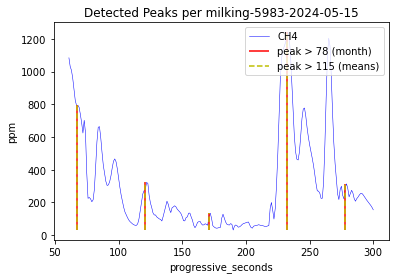

2
{2}


<Figure size 432x288 with 0 Axes>

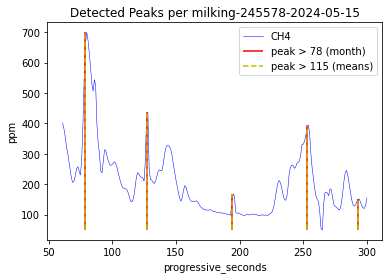

3
{3}


<Figure size 432x288 with 0 Axes>

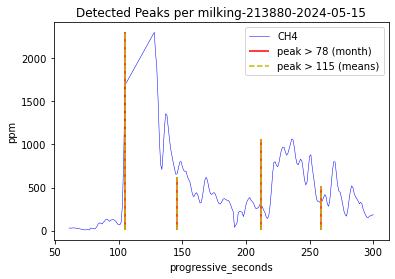

4
{4}


<Figure size 432x288 with 0 Axes>

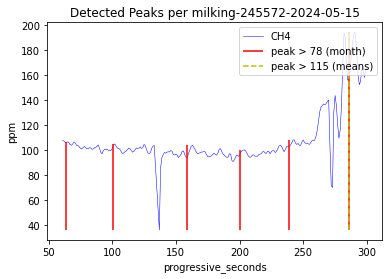

5
{5}


<Figure size 432x288 with 0 Axes>

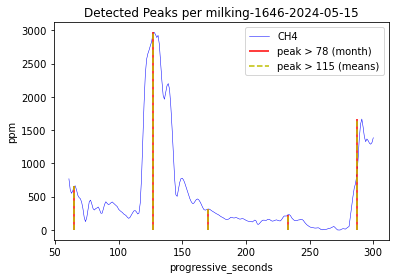

6
{6}


<Figure size 432x288 with 0 Axes>

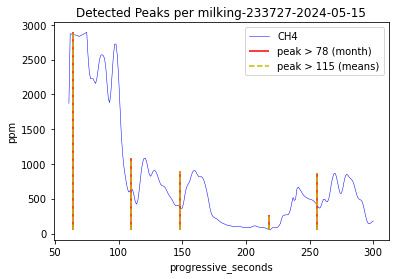

7
{7}


<Figure size 432x288 with 0 Axes>

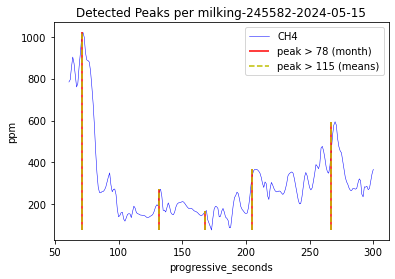

8
{8}


<Figure size 432x288 with 0 Axes>

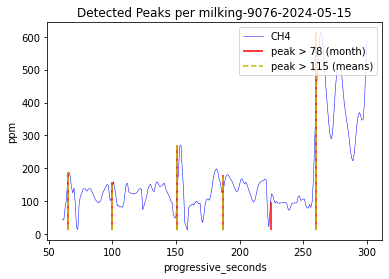

9
{9}


<Figure size 432x288 with 0 Axes>

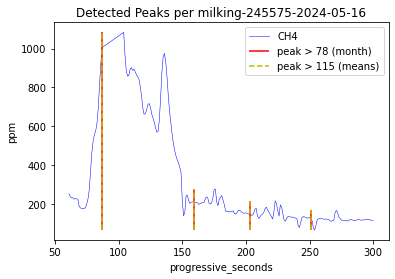

10
{10}


<Figure size 432x288 with 0 Axes>

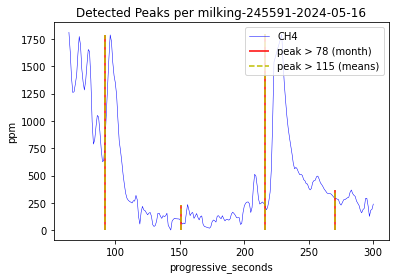

11
{11}


<Figure size 432x288 with 0 Axes>

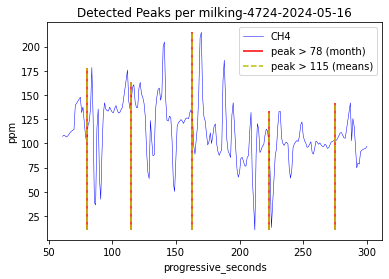

12
{12}


<Figure size 432x288 with 0 Axes>

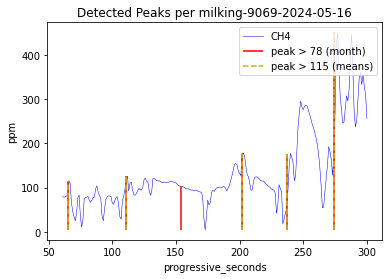

13
{13}


<Figure size 432x288 with 0 Axes>

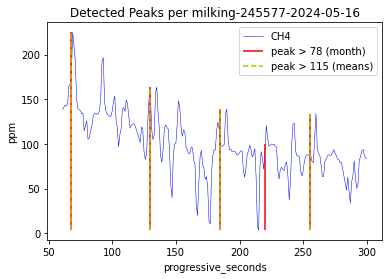

14
{14}


<Figure size 432x288 with 0 Axes>

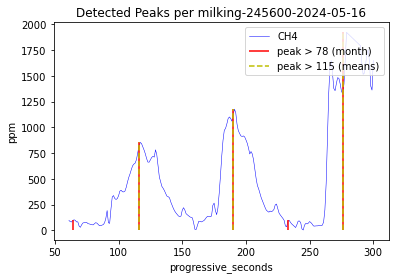

15
{15}


<Figure size 432x288 with 0 Axes>

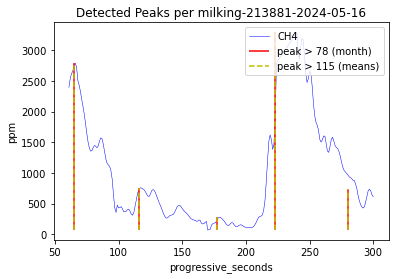

16
{16}


<Figure size 432x288 with 0 Axes>

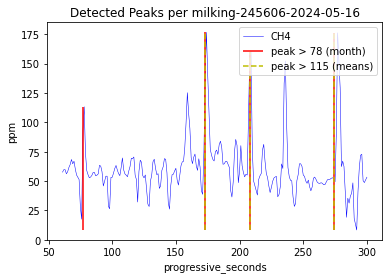

17
{17}


<Figure size 432x288 with 0 Axes>

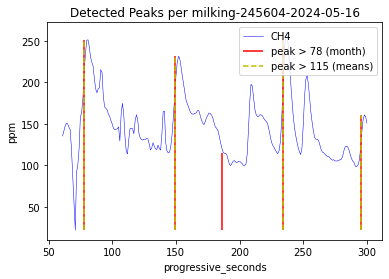

18
{18}


<Figure size 432x288 with 0 Axes>

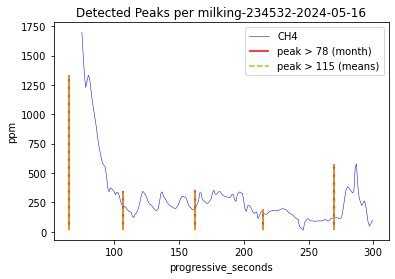

19
{19}


<Figure size 432x288 with 0 Axes>

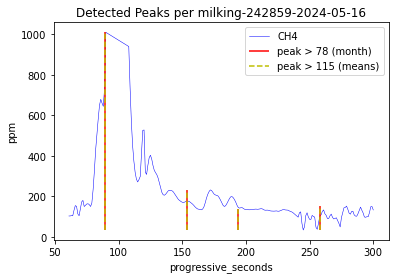

20
{20}


<Figure size 432x288 with 0 Axes>

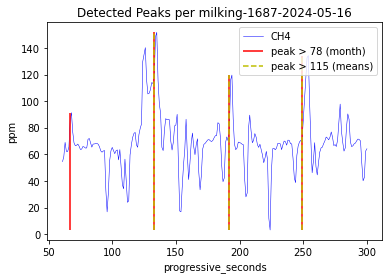

21
{21}


<Figure size 432x288 with 0 Axes>

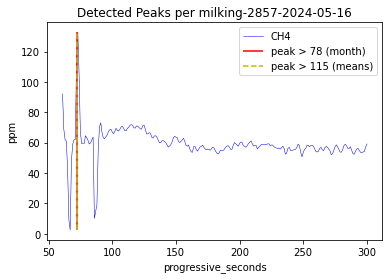

22
{22}


<Figure size 432x288 with 0 Axes>

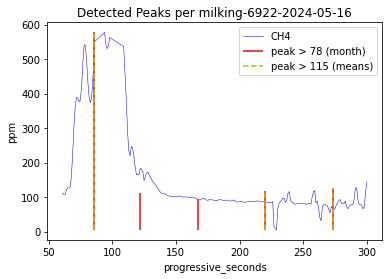

23
{23}


<Figure size 432x288 with 0 Axes>

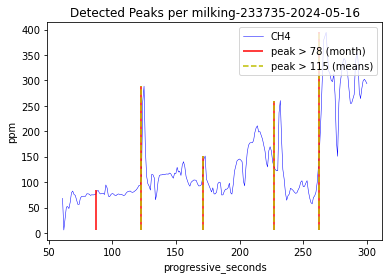

24
{24}


<Figure size 432x288 with 0 Axes>

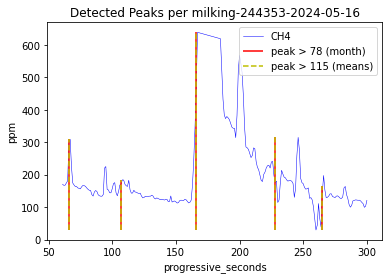

25
{25}


<Figure size 432x288 with 0 Axes>

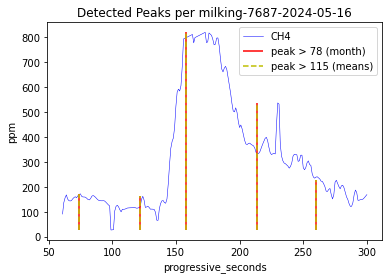

26
{26}


<Figure size 432x288 with 0 Axes>

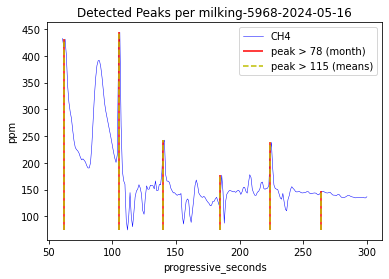

27
{27}


<Figure size 432x288 with 0 Axes>

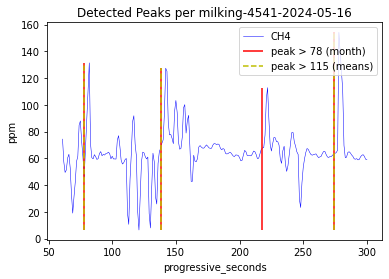

28
{28}


<Figure size 432x288 with 0 Axes>

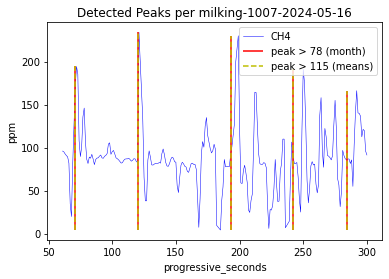

29
{29}


<Figure size 432x288 with 0 Axes>

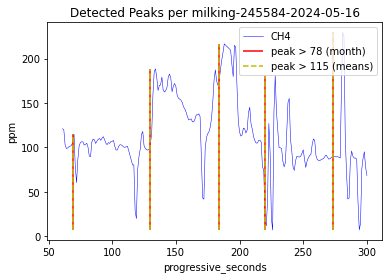

30
{30}


<Figure size 432x288 with 0 Axes>

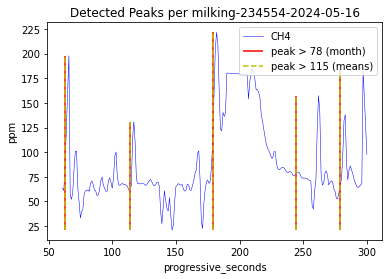

31
{31}


<Figure size 432x288 with 0 Axes>

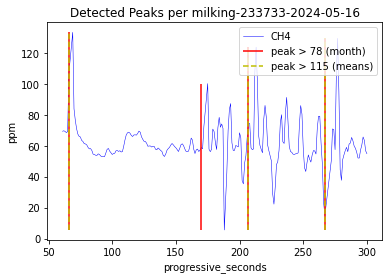

32
{32}


<Figure size 432x288 with 0 Axes>

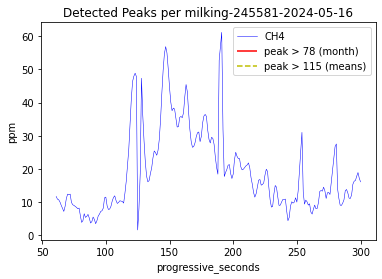

33
{33}


<Figure size 432x288 with 0 Axes>

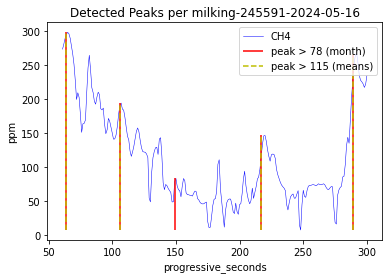

34
{34}


<Figure size 432x288 with 0 Axes>

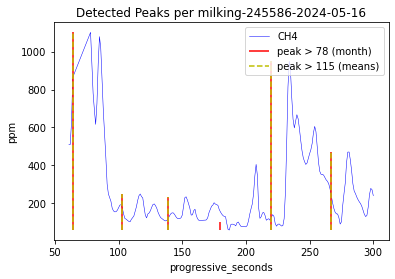

35
{35}


<Figure size 432x288 with 0 Axes>

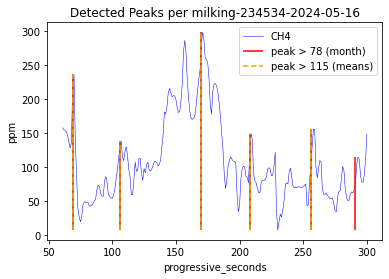

36
{36}


<Figure size 432x288 with 0 Axes>

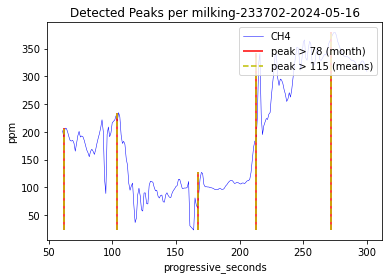

37
{37}


<Figure size 432x288 with 0 Axes>

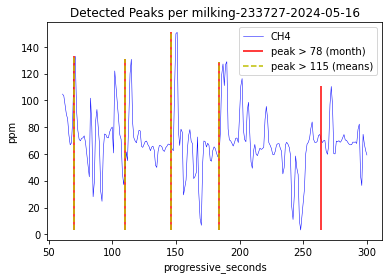

38
{38}


<Figure size 432x288 with 0 Axes>

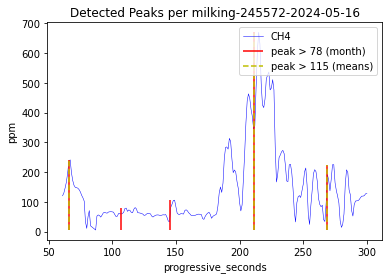

39
{39}


<Figure size 432x288 with 0 Axes>

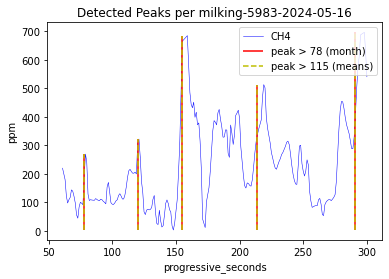

40
{40}


<Figure size 432x288 with 0 Axes>

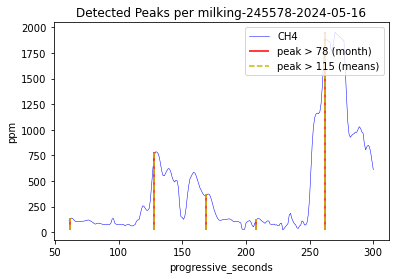

41
{41}


<Figure size 432x288 with 0 Axes>

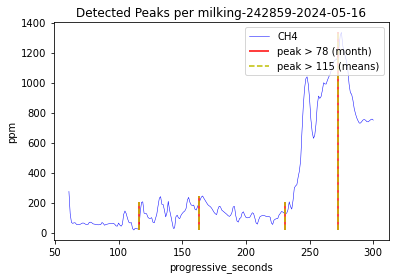

42
{42}


<Figure size 432x288 with 0 Axes>

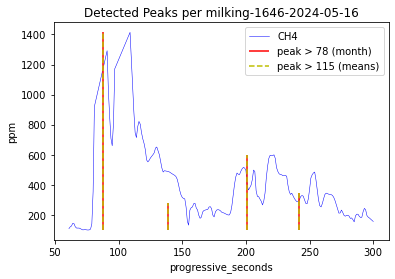

43
{43}


<Figure size 432x288 with 0 Axes>

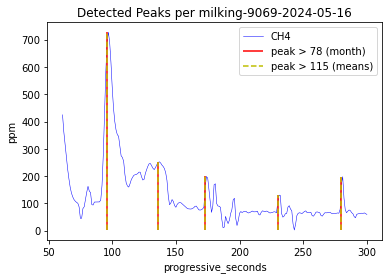

44
{44}


<Figure size 432x288 with 0 Axes>

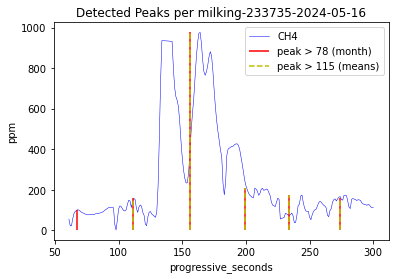

45
{45}


<Figure size 432x288 with 0 Axes>

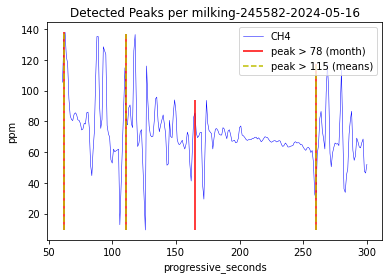

46
{46}


<Figure size 432x288 with 0 Axes>

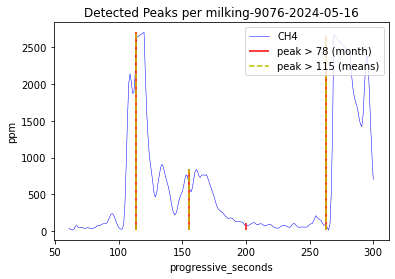

47
{47}


<Figure size 432x288 with 0 Axes>

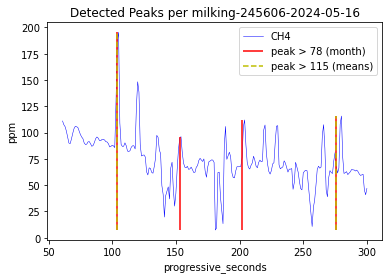

48
{48}


<Figure size 432x288 with 0 Axes>

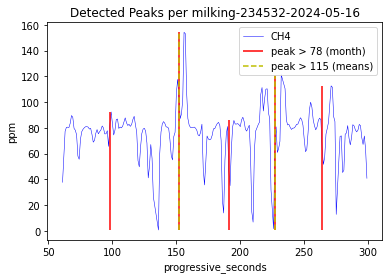

49
{49}


<Figure size 432x288 with 0 Axes>

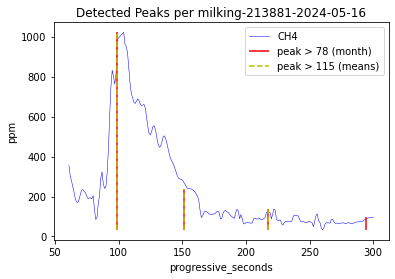

50
{50}


<Figure size 432x288 with 0 Axes>

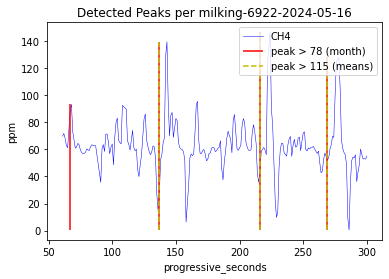

Mean 1 is:  219.72930820322608
Mean 2 is:  227.39568255395682


/tmp/ipykernel_940/3663461830.py:84: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filter_peaks.drop(columns=['Ora inizio',


In [6]:
mungiture_peaks = list()

for mungitura in mungiture[0:50]:  
    
    print(mungitura)
    
    milking_ch4 = mandria[mandria['Milking_number'] == mungitura]
    milking_ch4 = milking_ch4.reset_index(drop=True)
    print(set(milking_ch4['Milking_number']))
    #ch4=milking_ch4['CH4']
    
    animal = milking_ch4.iloc[0,5]
    date = milking_ch4.iloc[0,2]
    
    milking_ch4 = milking_ch4.set_index(milking_ch4['progressive_seconds'])

    
    #Wait 20 sec before the detection of the next peak
    time_interval=35
    
    # Find peaks
    peaks, properties = find_peaks(milking_ch4['CH4'], height=78, distance=time_interval)
    peaks_2, properties_2 = find_peaks(milking_ch4['CH4'], height=115, distance = time_interval )
    
    
    peaks_progressive = peaks + 60
    peaks_progressive_2 = peaks_2 + 60
    
    # Count the number of peaks
    num_peaks = len(peaks)
    
    
    # Save the count to a new column in the DataFrame
    milking_ch4['num_peaks'] = num_peaks
    
    
#if num_peaks >= 2:
    #print(mungitura)
    mungiture_peaks.append(mungitura)
    
    matrix.append(milking_ch4)
    
    
    seconds = np.array(milking_ch4['progressive_seconds'])
    
    
    #Plot singole mungiture 
    plt.figure(facecolor='white')
    
    milking_ch4.plot(y='CH4', linewidth=0.5, color = "blue")
    plt.vlines(peaks_progressive, ymin=min(milking_ch4['CH4']), ymax=properties['peak_heights'], color='r', linestyles='solid', label="peak > 78 (month)")
    plt.vlines(peaks_progressive_2, ymin=min(milking_ch4['CH4']), ymax=properties_2['peak_heights'], color='y', linestyles='dashed', label="peak > 115 (means)")
    plt.legend(loc='upper right')
    
    #plt.xlabel('Time')
    plt.ylabel('ppm')
    title = "Detected Peaks per milking" + "-" + str(animal) + "-" + str(date)
    #str(mungitura) + "-" + str(animal) + "-" + str(date) + "-picchi-taglio" 
    plt.title(title)
    
    '''
    directory = os.path.join("./dati_bufale/dati_settembre/protocollo_2/plot_bufale/peaks", str(animal))
    if not os.path.exists(directory):
        os.makedirs(directory)
    file_path = os.path.join(directory, (str(mungitura) + "-peaks.png"))
    plt.savefig(file_path, format="png", dpi=250)
    '''
    
    plt.show()   
    
      
      
 # Concatenate all DataFrames in the list into a single DataFrame
combined_df = pd.concat(matrix, ignore_index=True)

mean_ch4_1= combined_df['CH4'].mean()
print('Mean 1 is: ', mean_ch4_1)
filter_peaks=combined_df[combined_df['num_peaks']>= 2]

mean_ch4_2= filter_peaks['CH4'].mean()
print('Mean 2 is: ', mean_ch4_2)


filter_peaks.drop(columns=['Ora inizio',
                      'Milking_duration'], inplace=True)

# Salva il DataFrame combinato in un nuovo file CSV.
#output_file = './dati_bufale/dati_maggio_giugno/protocollo_2/ch4_peaks_filtered_500milkings.csv'
#filter_peaks.to_csv(output_file, index=False)

  
   